# Delivery Performance and Delay Analysis Using Python

## Project Objective

To analyze logistics delivery data, identify factors affecting delivery delays, calculate important KPIs, and explore how data science can improve delivery performance.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
data = pd.read_csv("../data/Delivery_Logistics.csv")
data.head()

,delivery_id,delivery_partner,package_type,vehicle_type,delivery_mode,region,weather_condition,distance_km,package_weight_kg,delivery_time_hours,expected_time_hours,delayed,delivery_status,delivery_rating,delivery_cost
0,250.99,delhivery,automobile parts,bike,same day,west,clear,297.0,46.96,1970-01-01 00:00:00.000000008,1970-01-01 00:00:00.000000008,no,delivered,3,1632.7206
1,250.99,xpressbees,cosmetics,ev van,express,central,cold,89.6,47.39,1970-01-01 00:00:00.000000002,1970-01-01 00:00:00.000000003,no,delivered,5,640.1700
2,250.99,shadowfax,groceries,truck,two day,east,rainy,273.5,26.89,1970-01-01 00:00:00.000000010,1970-01-01 00:00:00.000000016,no,delivered,4,1448.1700
3,250.99,dhl,electronics,ev van,same day,east,cold,269.7,12.69,1970-01-01 00:00:00.000000006,1970-01-01 00:00:00.000000008,no,delivered,3,1486.5700
4,250.99,dhl,clothing,van,two day,north,foggy,256.7,37.02,1970-01-01 00:00:00.000000009,1970-01-01 00:00:00.000000016,no,delivered,4,1394.5600


In [6]:
data.shape

(25000, 15)

In [7]:
data.columns

Index(['delivery_id', 'delivery_partner', 'package_type', 'vehicle_type',
       'delivery_mode', 'region', 'weather_condition', 'distance_km',
       'package_weight_kg', 'delivery_time_hours', 'expected_time_hours',
       'delayed', 'delivery_status', 'delivery_rating', 'delivery_cost'],
      dtype='object')

In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   delivery_id          25000 non-null  float64
 1   delivery_partner     25000 non-null  object 
 2   package_type         25000 non-null  object 
 3   vehicle_type         25000 non-null  object 
 4   delivery_mode        25000 non-null  object 
 5   region               25000 non-null  object 
 6   weather_condition    25000 non-null  object 
 7   distance_km          25000 non-null  float64
 8   package_weight_kg    25000 non-null  float64
 9   delivery_time_hours  25000 non-null  object 
 10  expected_time_hours  25000 non-null  object 
 11  delayed              25000 non-null  object 
 12  delivery_status      25000 non-null  object 
 13  delivery_rating      25000 non-null  int64  
 14  delivery_cost        25000 non-null  float64
dtypes: float64(4), int64(1), object(10)


In [9]:
data.isnull().sum()

delivery_id            0
delivery_partner       0
package_type           0
vehicle_type           0
delivery_mode          0
region                 0
weather_condition      0
distance_km            0
package_weight_kg      0
delivery_time_hours    0
expected_time_hours    0
delayed                0
delivery_status        0
delivery_rating        0
delivery_cost          0
dtype: int64

In [10]:
data.duplicated().sum()

0

In [11]:
data.describe()

,delivery_id,distance_km,package_weight_kg,delivery_rating,delivery_cost
count,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000
mean,12500.500000,150.390436,25.145898,3.666000,864.944579
std,7212.732314,86.409745,14.368663,1.149964,435.712593
min,250.990000,3.600000,0.670000,1.000000,95.667400
25%,6250.750000,75.900000,12.680000,3.000000,490.800000
50%,12500.500000,151.000000,25.145000,4.000000,867.535000
75%,18750.250000,224.900000,37.660000,5.000000,1237.910000
max,24750.010000,297.100000,49.520000,5.000000,1632.720600


In [12]:
data["delayed"].value_counts()

delayed
no     18331
yes     6669
Name: count, dtype: int64

In [13]:
data["delivery_status"].value_counts()

delivery_status
delivered    18331
delayed       5341
failed        1328
Name: count, dtype: int64

In [14]:
data["vehicle_type"].value_counts()

vehicle_type
ev bike    4218
van        4187
scooter    4174
bike       4160
truck      4145
ev van     4116
Name: count, dtype: int64

In [15]:
data["delivery_mode"].value_counts()

delivery_mode
two day     6302
same day    6279
express     6233
standard    6186
Name: count, dtype: int64

In [16]:
data["weather_condition"].value_counts()

weather_condition
foggy     4219
stormy    4198
rainy     4171
cold      4158
hot       4130
clear     4124
Name: count, dtype: int64

In [17]:
data["region"].value_counts()

region
west       5095
central    5060
south      4977
north      4949
east       4919
Name: count, dtype: int64

In [18]:
data[["delivery_time_hours", "expected_time_hours"]].dtypes

delivery_time_hours    object
expected_time_hours    object
dtype: object

In [19]:
data[["delivery_time_hours", "expected_time_hours"]].head(10)

,delivery_time_hours,expected_time_hours
0,1970-01-01 00:00:00.000000008,1970-01-01 00:00:00.000000008
1,1970-01-01 00:00:00.000000002,1970-01-01 00:00:00.000000003
2,1970-01-01 00:00:00.000000010,1970-01-01 00:00:00.000000016
3,1970-01-01 00:00:00.000000006,1970-01-01 00:00:00.000000008
4,1970-01-01 00:00:00.000000009,1970-01-01 00:00:00.000000016
5,1970-01-01 00:00:00.000000004,1970-01-01 00:00:00.000000002
6,1970-01-01 00:00:00.000000006,1970-01-01 00:00:00.000000008
7,1970-01-01 00:00:00.000000004,1970-01-01 00:00:00.000000008
8,1970-01-01 00:00:00.000000005,1970-01-01 00:00:00.000000008
9,1970-01-01 00:00:00.000000003,1970-01-01 00:00:00.000000008


In [20]:
print(data["delivery_time_hours"].head(20).tolist())

['1970-01-01 00:00:00.000000008', '1970-01-01 00:00:00.000000002', '1970-01-01 00:00:00.000000010', '1970-01-01 00:00:00.000000006', '1970-01-01 00:00:00.000000009', '1970-01-01 00:00:00.000000004', '1970-01-01 00:00:00.000000006', '1970-01-01 00:00:00.000000004', '1970-01-01 00:00:00.000000005', '1970-01-01 00:00:00.000000003', '1970-01-01 00:00:00.000000005', '1970-01-01 00:00:00.000000003', '1970-01-01 00:00:00.000000008', '1970-01-01 00:00:00.000000006', '1970-01-01 00:00:00.000000012', '1970-01-01 00:00:00.000000008', '1970-01-01 00:00:00.000000010', '1970-01-01 00:00:00.000000011', '1970-01-01 00:00:00.000000004', '1970-01-01 00:00:00.000000007']


In [21]:
print(data["expected_time_hours"].head(20).tolist())

['1970-01-01 00:00:00.000000008', '1970-01-01 00:00:00.000000003', '1970-01-01 00:00:00.000000016', '1970-01-01 00:00:00.000000008', '1970-01-01 00:00:00.000000016', '1970-01-01 00:00:00.000000002', '1970-01-01 00:00:00.000000008', '1970-01-01 00:00:00.000000008', '1970-01-01 00:00:00.000000008', '1970-01-01 00:00:00.000000008', '1970-01-01 00:00:00.000000008', '1970-01-01 00:00:00.000000016', '1970-01-01 00:00:00.000000016', '1970-01-01 00:00:00.000000002', '1970-01-01 00:00:00.000000016', '1970-01-01 00:00:00.000000006', '1970-01-01 00:00:00.000000024', '1970-01-01 00:00:00.000000024', '1970-01-01 00:00:00.000000008', '1970-01-01 00:00:00.000000003']


In [22]:
print(data["delayed"].value_counts())

delayed
no     18331
yes     6669
Name: count, dtype: int64


In [23]:
print(data["delivery_status"].value_counts())

delivery_status
delivered    18331
delayed       5341
failed        1328
Name: count, dtype: int64


In [24]:
print(data["delivery_time_hours"].head(20).tolist())

['1970-01-01 00:00:00.000000008', '1970-01-01 00:00:00.000000002', '1970-01-01 00:00:00.000000010', '1970-01-01 00:00:00.000000006', '1970-01-01 00:00:00.000000009', '1970-01-01 00:00:00.000000004', '1970-01-01 00:00:00.000000006', '1970-01-01 00:00:00.000000004', '1970-01-01 00:00:00.000000005', '1970-01-01 00:00:00.000000003', '1970-01-01 00:00:00.000000005', '1970-01-01 00:00:00.000000003', '1970-01-01 00:00:00.000000008', '1970-01-01 00:00:00.000000006', '1970-01-01 00:00:00.000000012', '1970-01-01 00:00:00.000000008', '1970-01-01 00:00:00.000000010', '1970-01-01 00:00:00.000000011', '1970-01-01 00:00:00.000000004', '1970-01-01 00:00:00.000000007']


In [25]:
print(data["expected_time_hours"].head(20).tolist())

['1970-01-01 00:00:00.000000008', '1970-01-01 00:00:00.000000003', '1970-01-01 00:00:00.000000016', '1970-01-01 00:00:00.000000008', '1970-01-01 00:00:00.000000016', '1970-01-01 00:00:00.000000002', '1970-01-01 00:00:00.000000008', '1970-01-01 00:00:00.000000008', '1970-01-01 00:00:00.000000008', '1970-01-01 00:00:00.000000008', '1970-01-01 00:00:00.000000008', '1970-01-01 00:00:00.000000016', '1970-01-01 00:00:00.000000016', '1970-01-01 00:00:00.000000002', '1970-01-01 00:00:00.000000016', '1970-01-01 00:00:00.000000006', '1970-01-01 00:00:00.000000024', '1970-01-01 00:00:00.000000024', '1970-01-01 00:00:00.000000008', '1970-01-01 00:00:00.000000003']


In [26]:
# Convert the time columns back to numeric hour values

data["delivery_time_hours"] = pd.to_datetime(
    data["delivery_time_hours"]
).dt.nanosecond

data["expected_time_hours"] = pd.to_datetime(
    data["expected_time_hours"]
).dt.nanosecond

# Check the result
print(data[["delivery_time_hours", "expected_time_hours"]].head(10))

   delivery_time_hours  expected_time_hours
0                    8                    8
1                    2                    3
2                   10                   16
3                    6                    8
4                    9                   16
5                    4                    2
6                    6                    8
7                    4                    8
8                    5                    8
9                    3                    8


In [27]:
print(data[["delivery_time_hours", "expected_time_hours"]].describe())

       delivery_time_hours  expected_time_hours
count         25000.000000         25000.000000
mean              6.248040            13.107680
std               3.140935             7.559024
min               0.000000             2.000000
25%               4.000000             8.000000
50%               6.000000             8.000000
75%               8.000000            16.000000
max              19.000000            24.000000


In [28]:
print(data[[
    "distance_km",
    "package_weight_kg",
    "delivery_time_hours",
    "expected_time_hours",
    "delivery_rating",
    "delivery_cost"
]].describe())

        distance_km  package_weight_kg  delivery_time_hours  \
count  25000.000000       25000.000000         25000.000000   
mean     150.390436          25.145898             6.248040   
std       86.409745          14.368663             3.140935   
min        3.600000           0.670000             0.000000   
25%       75.900000          12.680000             4.000000   
50%      151.000000          25.145000             6.000000   
75%      224.900000          37.660000             8.000000   
max      297.100000          49.520000            19.000000   

       expected_time_hours  delivery_rating  delivery_cost  
count         25000.000000     25000.000000   25000.000000  
mean             13.107680         3.666000     864.944579  
std               7.559024         1.149964     435.712593  
min               2.000000         1.000000      95.667400  
25%               8.000000         3.000000     490.800000  
50%               8.000000         4.000000     867.535000  
75%  

In [29]:
pd.crosstab(data["delayed"], data["delivery_status"])

delivery_status,delayed,delivered,failed
delayed,,,
no,0,18331,0
yes,5341,0,1328


In [36]:
print("========== LOGISTICS KPIs ==========")
print("Total Deliveries:", total_deliveries)
print("Delayed Deliveries:", delayed_deliveries)
print("Delay Rate:", round(delay_rate, 2), "%")
print("On-Time Delivery Rate:", round(on_time_rate, 2), "%")
print("Average Delivery Time:", round(average_delivery_time, 2), "hours")
print("Average Delivery Cost:", round(average_delivery_cost, 2))

========== LOGISTICS KPIs ==========
Total Deliveries: 25000
Delayed Deliveries: 6669
Delay Rate: 26.68 %
On-Time Delivery Rate: 73.32 %
Average Delivery Time: 6.25 hours
Average Delivery Cost: 864.94


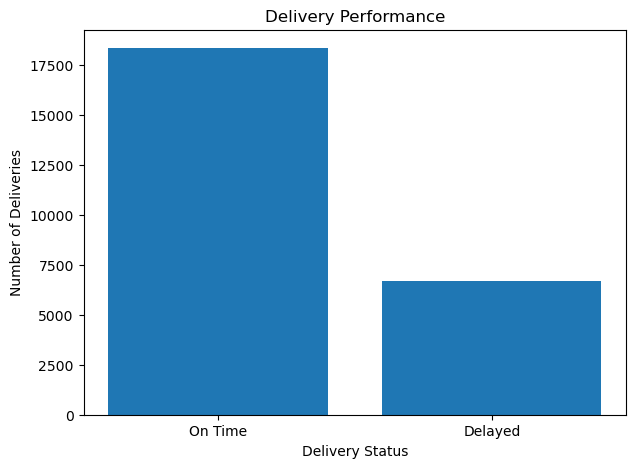

In [38]:
status_counts = data["delayed"].value_counts()

plt.figure(figsize=(7, 5))
plt.bar(
    ["On Time", "Delayed"],
    [status_counts.get("no", 0), status_counts.get("yes", 0)]
)

plt.title("Delivery Performance")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Deliveries")

plt.savefig("../visualizations/delivery_performance.png", dpi=300, bbox_inches="tight")

plt.show()

In [39]:
weather_delay = pd.crosstab(
    data["weather_condition"],
    data["delayed"],
    normalize="index"
) * 100

print(weather_delay)

delayed                   no        yes
weather_condition                      
clear              82.565470  17.434530
cold               83.982684  16.017316
foggy              69.684759  30.315241
hot                82.881356  17.118644
rainy              62.646847  37.353153
stormy             58.551691  41.448309


In [40]:
weather_delay = weather_delay.rename(
    columns={"no": "On Time (%)", "yes": "Delayed (%)"}
)

print(weather_delay.round(2))

delayed            On Time (%)  Delayed (%)
weather_condition                          
clear                    82.57        17.43
cold                     83.98        16.02
foggy                    69.68        30.32
hot                      82.88        17.12
rainy                    62.65        37.35
stormy                   58.55        41.45


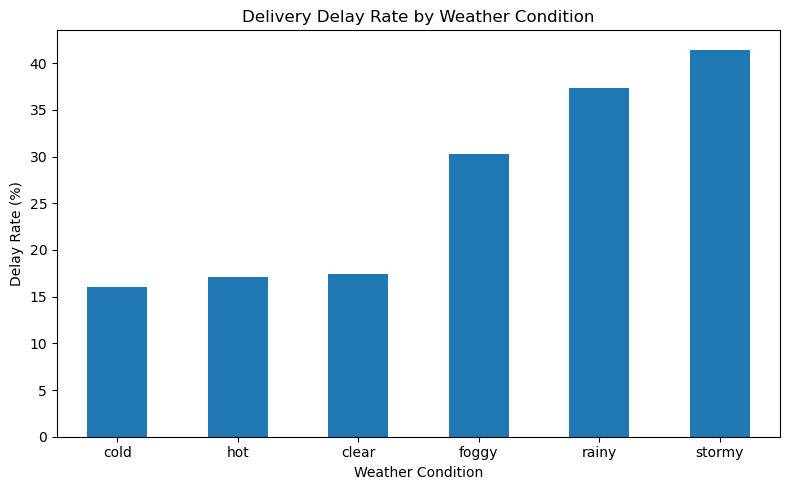

In [41]:
weather_delay["Delayed (%)"].sort_values().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Delivery Delay Rate by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Delay Rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "../visualizations/delay_by_weather.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [42]:
worst_weather = weather_delay["Delayed (%)"].idxmax()
worst_weather_rate = weather_delay["Delayed (%)"].max()

print("Weather condition with highest delay rate:", worst_weather)
print("Delay rate:", round(worst_weather_rate, 2), "%")

Weather condition with highest delay rate: stormy
Delay rate: 41.45 %


In [43]:
import os
print(os.getcwd())

C:\Users\nived\desktop\delivery-performance-analysis\notebooks


In [47]:
worst_weather = weather_delay["Delayed (%)"].idxmax()
worst_weather_rate = weather_delay["Delayed (%)"].max()

print("Highest delay weather:", worst_weather)
print("Delay rate:", round(worst_weather_rate, 2), "%")

Highest delay weather: stormy
Delay rate: 41.45 %


In [48]:
vehicle_delay = pd.crosstab(
    data["vehicle_type"],
    data["delayed"],
    normalize="index"
) * 100

vehicle_delay = vehicle_delay.rename(
    columns={"no": "On Time (%)", "yes": "Delayed (%)"}
)

print(vehicle_delay.round(2))

delayed       On Time (%)  Delayed (%)
vehicle_type                          
bike                72.96        27.04
ev bike             73.57        26.43
ev van              73.37        26.63
scooter             73.86        26.14
truck               72.96        27.04
van                 73.23        26.77


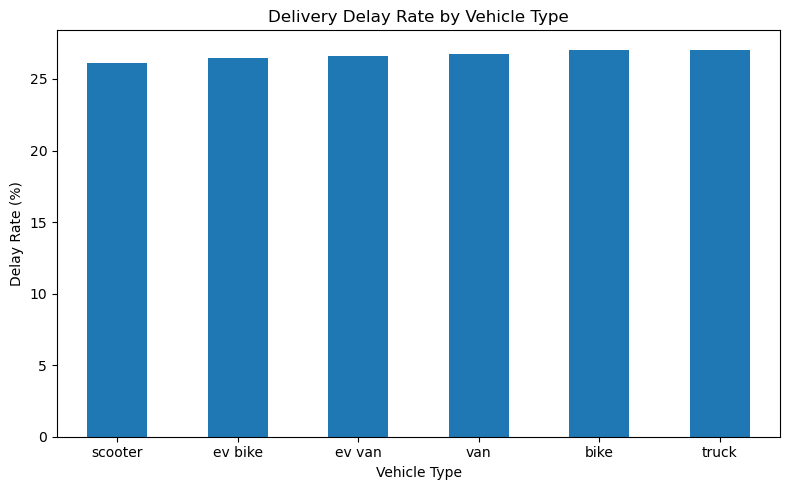

In [49]:
vehicle_delay["Delayed (%)"].sort_values().plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Delivery Delay Rate by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Delay Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "../visualizations/delay_by_vehicle.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [50]:
mode_delay = pd.crosstab(
    data["delivery_mode"],
    data["delayed"],
    normalize="index"
) * 100

mode_delay = mode_delay.rename(
    columns={"no": "On Time (%)", "yes": "Delayed (%)"}
)

print(mode_delay.round(2))

delayed        On Time (%)  Delayed (%)
delivery_mode                          
express              26.22        73.78
same day             67.46        32.54
standard            100.00         0.00
two day              99.57         0.43


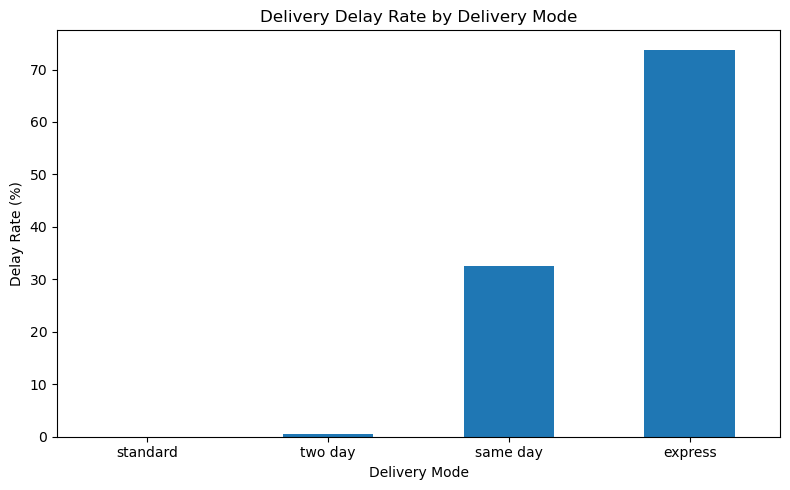

In [51]:
mode_delay["Delayed (%)"].sort_values().plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Delivery Delay Rate by Delivery Mode")
plt.xlabel("Delivery Mode")
plt.ylabel("Delay Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "../visualizations/delay_by_mode.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

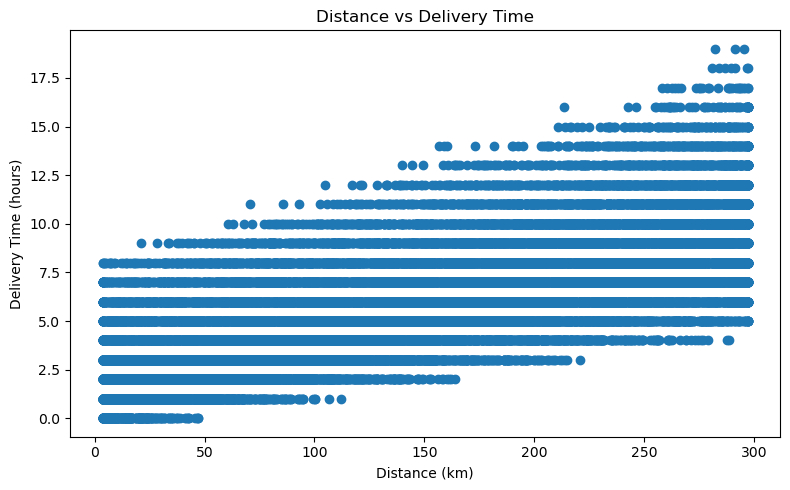

In [52]:
plt.figure(figsize=(8,5))

plt.scatter(
    data["distance_km"],
    data["delivery_time_hours"]
)

plt.xlabel("Distance (km)")
plt.ylabel("Delivery Time (hours)")
plt.title("Distance vs Delivery Time")

plt.tight_layout()

plt.savefig(
    "../visualizations/distance_vs_delivery_time.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()